# Fokker-Planck radial (cilíndrico) con volumen excluido

$$
\partial_t P = -\frac{1}{r}\,\partial_r\big(r\,J\big),\qquad
J = v(r)\,P\left(1-\frac{P}{P_{max}}\right) - D\,\partial_r P
$$

- $v(r) = -U'(r)/\gamma$ es la deriva ($v<0$ empuja hacia el centro).
- $(1-P/P_{max})$ apaga la advección cuando la densidad local llega a $P_{max}$.
- Estacionario con flujo nulo: $P = P_{max}/\big(1+e^{(U-\mu)/D}\big)$ (Fermi-Dirac).

El solver está en `fokker_planck.py`. Para "quitar" el volumen excluido basta con poner `P_max` muy grande (p.ej. `1e12`).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as w
from fokker_planck import RadialFokkerPlanck, steep_trap_drift, step_trap_drift

plt.rcParams["figure.dpi"] = 110

## 1. Simulación básica

Cambia los parámetros y vuelve a ejecutar la celda.

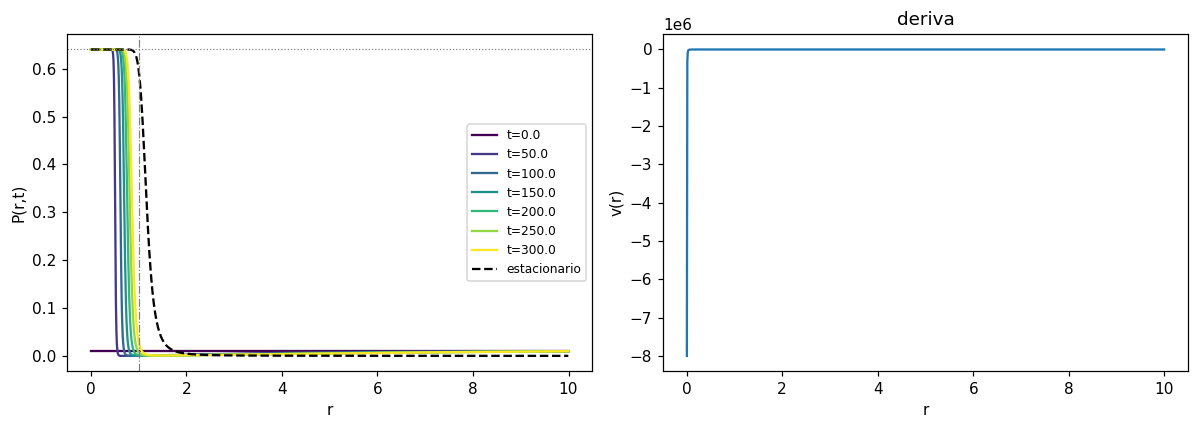

conservación de masa: 3.141592653589793 -> 3.729503654485952


In [27]:
# --- dominio y malla
R, N = 10.0, 1000
# --- física
c_inf = 0.01
D     = 0.05      # difusión
P_max = 0.64      # densidad máxima (empaquetamiento)
v0, r_trap, n = 1.0, 1.0, -2          # trampa U ∝ r^n  ->  v = -v0 (r/r_trap)^(n-1)
drift = steep_trap_drift(v0, r_trap, n)
# --- condición inicial y tiempo
P0 = np.full(N, c_inf)
t_end, n_out = 300.0, 7

fp = RadialFokkerPlanck(R, N, D, drift, P_max, outer_bc="dirichlet", P_outer=c_inf)
t, P = fp.solve(P0, t_end, n_out=n_out)
P_ss = fp.steady_state(fp.mass(P0))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
cmap = plt.cm.viridis(np.linspace(0, 1, len(t)))
for k in range(len(t)):
    ax[0].plot(fp.r, P[:, k], color=cmap[k], label=f"t={t[k]:.1f}")
ax[0].plot(fp.r, P_ss, "k--", label="estacionario")
ax[0].axhline(P_max, color="gray", ls=":", lw=0.8)
ax[0].axvline(r_trap, color="gray", ls="-.", lw=0.8)
ax[0].set(xlabel="r", ylabel="P(r,t)"); ax[0].legend(fontsize=8)

ax[1].plot(fp.r, drift(fp.r))
ax[1].set(xlabel="r", ylabel="v(r)", title="deriva")
plt.tight_layout(); plt.show()

print("conservación de masa:", fp.mass(P0), "->", fp.mass(P[:, -1]))

## 4. Tu propia deriva

Define cualquier `v(r)` (o un potencial y deriva numéricamente). La única condición es que acepte arrays de numpy.

In [ ]:
# Ejemplo: trampa armónica + barrera repulsiva gaussiana en r=1.5
def mi_deriva(r):
    r = np.asarray(r)
    A, s = 0.15, 0.1   # U = r²/4 + A exp(-(r-1.5)²/2s²),  v = -U'
    return -0.5 * r + A * (r - 1.5) / s**2 * np.exp(-(r - 1.5)**2 / (2 * s**2))

R, N, D, P_max = 3.0, 400, 0.05, 0.64
P0 = np.full(N, 0.2)

fp = RadialFokkerPlanck(R, N, D, mi_deriva, P_max)
t, P = fp.solve(P0, 50.0, n_out=6)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k in range(len(t)):
    ax[0].plot(fp.r, P[:, k], label=f"t={t[k]:.0f}")
ax[0].plot(fp.r, fp.steady_state(fp.mass(P0)), "k--", label="estacionario")
ax[0].axhline(P_max, color="gray", ls=":", lw=0.8)
ax[0].set(xlabel="r", ylabel="P"); ax[0].legend(fontsize=8)
ax[1].plot(fp.r, mi_deriva(fp.r)); ax[1].set(xlabel="r", ylabel="v(r)")
plt.tight_layout(); plt.show()